
<div style="text-align:center; margin-top:40px;">

<img src="img/logoitqv1.jpg" width="600"/>

<h1 style="
font-family:'Times New Roman', serif;
font-size:42px;
font-weight:bold;
margin-bottom:10px;
">
Caso Práctico: Neurona de McCulloch y Pitts
</h1>

<p style="
font-family:'Times New Roman', serif;
font-size:22px;
">
12 de Octubre de 2026
</p>

<h2 style="
font-family:'Times New Roman', serif;
font-size:28px;
font-weight:bold;
margin-top:35px;
">
Aplicación de la MP Neurona a un caso práctico real
</h2>

<p style="
font-family:'Times New Roman', serif;
font-size:22px;
margin-bottom:8px;
">
Kevin Xavier Suasnavas Villarreal
</p>

<p style="
font-family:'Times New Roman', serif;
font-size:18px;
margin-top:0px;
">
<a href="https://github.com/kevinsuas433/Machine2026.git">
<strong>Link a mi GitHub</strong>
</a>

https://github.com/kevinsuas433/Machine2026.git

</p>

</div>

---
  

# Caso práctico: Neurona de McCulloch y Pitts

## 1. Introducción

En esta práctica se implementa una neurona de McCulloch y Pitts (MP) para clasificar muestras del conjunto de datos **Breast Cancer Wisconsin**. El objetivo es comprender cómo una neurona sencilla puede producir una salida binaria a partir de características numéricas previamente transformadas.

Este ejercicio tiene fines académicos. **No es una herramienta médica y sus resultados no deben utilizarse para diagnosticar ni tomar decisiones clínicas.**

## 2. Objetivo general

- **Implementar** una neurona de McCulloch y Pitts que clasifique muestras del conjunto Breast Cancer Wisconsin, preparar sus datos, evaluar su desempeño y guardar la configuración necesaria para conectarla posteriormente con una API.

## 3. Descripción del conjunto de datos

El conjunto está incluido en `scikit-learn` y contiene 30 características numéricas calculadas a partir de imágenes digitalizadas de muestras de tejido mamario. Las etiquetas representan dos clases: maligno y benigno.

En la codificación original de `scikit-learn`:

- `0`: maligno.
- `1`: benigno.

La neurona de esta práctica genera una salida `0` o `1`, por lo que conservaremos esa correspondencia.

## 4. Importación de bibliotecas

En esta celda importamos las herramientas que utilizaremos para cargar los datos, organizarlos, dividirlos, evaluar el modelo y guardar su configuración.

In [1]:
# Importamos las bibliotecas necesarias para desarrollar la práctica.
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Bibliotecas importadas correctamente.")

Bibliotecas importadas correctamente.


## 5. Carga y exploración inicial de los datos

Cargamos el conjunto de datos y revisamos cuántas muestras y características contiene. También consultamos los nombres de las clases para interpretar correctamente las predicciones.

In [2]:
# Cargamos el conjunto de datos incluido en scikit-learn.
cancer_mama = load_breast_cancer()

# Organizamos las características en un DataFrame para facilitar su revisión.
X = pd.DataFrame(
    cancer_mama.data,
    columns=cancer_mama.feature_names
)

# Guardamos las etiquetas reales de cada muestra.
y = pd.Series(cancer_mama.target, name="diagnostico")

print("Número de muestras:", X.shape[0])
print("Número de características:", X.shape[1])
print("Clases:", dict(enumerate(cancer_mama.target_names)))
print("\nPrimeras cinco muestras:")
display(X.head())

Número de muestras: 569
Número de características: 30
Clases: {0: np.str_('malignant'), 1: np.str_('benign')}

Primeras cinco muestras:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


malignant    212
benign       357
Name: count, dtype: int64


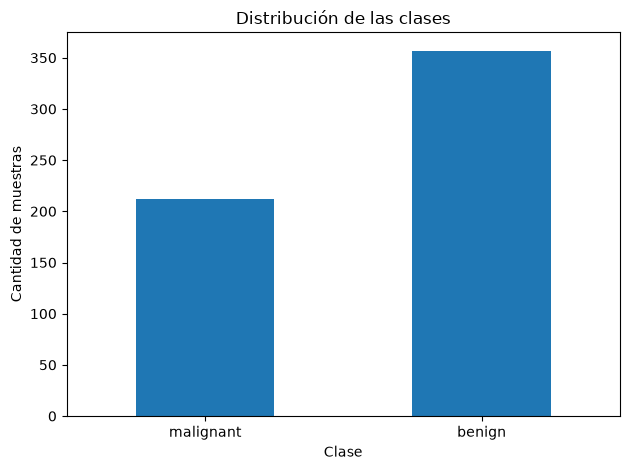

In [3]:
# Revisamos la distribución de las dos clases del conjunto de datos.
distribucion = y.value_counts().sort_index()
distribucion.index = [cancer_mama.target_names[i] for i in distribucion.index]

print(distribucion)

# Representamos la cantidad de muestras de cada clase.
distribucion.plot(kind="bar", rot=0, title="Distribución de las clases")
plt.xlabel("Clase")
plt.ylabel("Cantidad de muestras")
plt.tight_layout()
plt.show()

## 6. División en entrenamiento y prueba

Separamos el conjunto de datos antes de calcular los límites de la transformación binaria. De esta manera, los límites se obtienen solamente del entrenamiento y después se aplican al conjunto de prueba.

Usamos `stratify=y` para mantener aproximadamente la proporción de las clases, y `random_state=42` para que la división sea reproducible.

In [4]:
# Reservamos el 25 % de las muestras para evaluar el modelo.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Muestras de entrenamiento:", len(X_train))
print("Muestras de prueba:", len(X_test))
print("Características por muestra:", X_train.shape[1])

Muestras de entrenamiento: 426
Muestras de prueba: 143
Características por muestra: 30


## 7. Preparación de las características binarias

La neurona MP recibe entradas binarias. Por eso, convertimos cada característica numérica a `1` o `0` utilizando como punto de separación el punto medio entre el mínimo y el máximo observados en el conjunto de entrenamiento de esa característica.

- Los valores menores o iguales al punto medio se convierten en `1`.
- Los valores mayores al punto medio se convierten en `0`.

Guardamos esos puntos medios para aplicar exactamente la misma transformación cuando lleguen nuevas muestras a la API. Esta transformación es una simplificación para fines didácticos; no implica que sea la mejor preparación posible para un problema médico.

In [5]:
# Calculamos un punto medio por característica usando solo entrenamiento.
puntos_corte = {
    columna: float(
        (X_train[columna].min() + X_train[columna].max()) / 2
    )
    for columna in X_train.columns
}

def transformar_a_binario(datos, puntos):
    """Convierte las características numéricas en entradas binarias."""
    resultado = pd.DataFrame(index=datos.index)

    for columna in puntos:
        # Un valor bajo o igual al punto medio recibe 1; uno mayor recibe 0.
        resultado[columna] = (datos[columna] <= puntos[columna]).astype(int)

    return resultado

# Aplicamos la misma regla tanto al entrenamiento como a la prueba.
X_train_bin = transformar_a_binario(X_train, puntos_corte)
X_test_bin = transformar_a_binario(X_test, puntos_corte)

print("Dimensiones del entrenamiento binario:", X_train_bin.shape)
print("Dimensiones de la prueba binaria:", X_test_bin.shape)
print("¿Hay valores nulos en entrenamiento?:", X_train_bin.isna().any().any())
print("¿Hay valores nulos en prueba?:", X_test_bin.isna().any().any())

display(X_train_bin.head())

Dimensiones del entrenamiento binario: (426, 30)
Dimensiones de la prueba binaria: (143, 30)
¿Hay valores nulos en entrenamiento?: False
¿Hay valores nulos en prueba?: False


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
517,0,1,0,1,0,1,1,1,1,1,...,0,1,0,1,1,1,1,0,1,1
287,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
25,1,1,1,1,0,0,0,0,0,0,...,0,1,0,1,0,1,1,0,1,1
253,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1
369,0,1,0,0,0,0,0,0,1,1,...,0,1,0,0,1,1,1,0,1,1


### 7.1. Ejemplo de una característica

El siguiente gráfico muestra la distribución de `mean radius` y el punto medio usado para convertir esa característica a valores binarios.

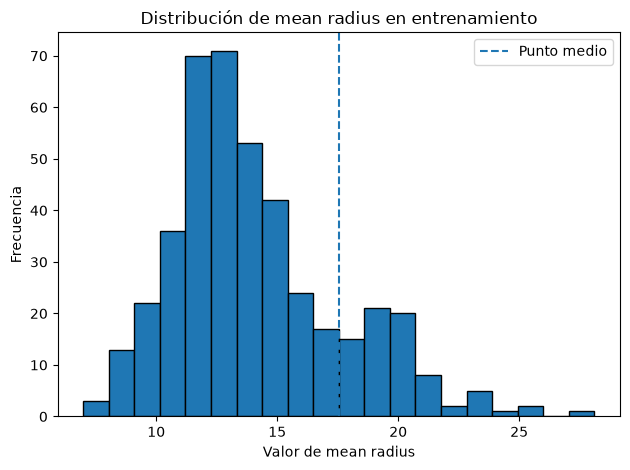

In [6]:
# Dibujamos un histograma para observar una de las características.
caracteristica_ejemplo = "mean radius"
plt.hist(X_train[caracteristica_ejemplo], bins=20, edgecolor="black")
plt.axvline(
    puntos_corte[caracteristica_ejemplo],
    linestyle="--",
    label="Punto medio"
)
plt.title("Distribución de mean radius en entrenamiento")
plt.xlabel("Valor de mean radius")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Implementación de la neurona de McCulloch y Pitts

La neurona suma los valores binarios de una muestra. Si la suma alcanza o supera el umbral, devuelve `1`; de lo contrario, devuelve `0`.

El método `fit` prueba los umbrales posibles y elige el que obtiene mayor exactitud en el conjunto de entrenamiento. Este procedimiento es sencillo y útil para comprender el concepto, aunque no equivale a un entrenamiento moderno de redes neuronales.

In [8]:
class MpNeuron:
    def __init__(self):
        # El umbral se determinará durante el entrenamiento.
        self.threshold = None

    def model(self, x):
        # Sumamos las entradas binarias de una muestra.
        suma_entradas = int(np.sum(x))

        # La salida es 1 si la suma alcanza el umbral; en caso contrario, 0.
        return int(suma_entradas >= self.threshold)

    def predict(self, X):
        # Aplicamos la neurona a cada fila del conjunto recibido.
        return np.array([self.model(x) for x in X], dtype=int)

    def fit(self, X, y):
        # Probamos todos los umbrales posibles, desde 0 hasta el número
        # de características, y conservamos el de mejor exactitud.
        mejor_exactitud = -1.0
        mejor_umbral = 0

        for umbral in range(X.shape[1] + 1):
            self.threshold = umbral
            predicciones = self.predict(X)
            exactitud = accuracy_score(y, predicciones)

            if exactitud > mejor_exactitud:
                mejor_exactitud = exactitud
                mejor_umbral = umbral

        self.threshold = mejor_umbral
        return self

## 9. Entrenamiento de la neurona

Entrenamos la neurona con las características binarias y las etiquetas del conjunto de entrenamiento. Después mostramos el umbral seleccionado y la exactitud obtenida sobre esos mismos datos.

In [9]:
# Creamos y entrenamos la neurona MP.
np_neurona = MpNeuron()
np_neurona.fit(X_train_bin.to_numpy(dtype=int), y_train.to_numpy(dtype=int))

predicciones_train = np_neurona.predict(X_train_bin.to_numpy(dtype=int))
exactitud_train = accuracy_score(y_train, predicciones_train)

print("Umbral seleccionado:", np_neurona.threshold)
print(f"Exactitud en entrenamiento: {exactitud_train:.2%}")

Umbral seleccionado: 27
Exactitud en entrenamiento: 86.62%


## 10. Evaluación con el conjunto de prueba

Ahora evaluamos las predicciones con datos que no se utilizaron para elegir el umbral. La exactitud indica la proporción total de predicciones correctas; también revisamos la matriz de confusión y otras métricas por clase para tener una visión más completa.

Una exactitud alta por sí sola no garantiza que el modelo sea adecuado para uso clínico.

In [10]:
# Predecimos las clases del conjunto de prueba.
Y_pred = np_neurona.predict(X_test_bin.to_numpy(dtype=int))

# Calculamos la exactitud de las predicciones de prueba.
accuracy = accuracy_score(y_test, Y_pred)
print(f"Exactitud en prueba: {accuracy:.2%}")

# La matriz utiliza el orden de etiquetas 0 = maligno y 1 = benigno.
matriz = confusion_matrix(y_test, Y_pred, labels=[0, 1])
print("\nMatriz de confusión (filas = clase real, columnas = clase predicha):")
print(matriz)

print("\nInforme de clasificación:")
print(classification_report(
    y_test,
    Y_pred,
    labels=[0, 1],
    target_names=["maligno (0)", "benigno (1)"],
    zero_division=0
))

Exactitud en prueba: 88.81%

Matriz de confusión (filas = clase real, columnas = clase predicha):
[[39 14]
 [ 2 88]]

Informe de clasificación:
              precision    recall  f1-score   support

 maligno (0)       0.95      0.74      0.83        53
 benigno (1)       0.86      0.98      0.92        90

    accuracy                           0.89       143
   macro avg       0.91      0.86      0.87       143
weighted avg       0.90      0.89      0.88       143



### 10.1. Visualización de la matriz de confusión

La matriz permite comparar las clases reales con las predichas. Las filas representan la clase real y las columnas la clase predicha.

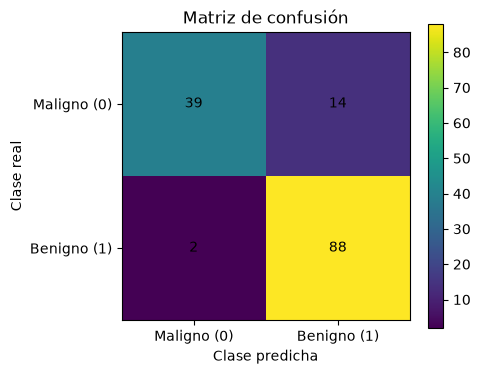

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
imagen = ax.imshow(matriz)
ax.set_title("Matriz de confusión")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_xticks([0, 1], labels=["Maligno (0)", "Benigno (1)"])
ax.set_yticks([0, 1], labels=["Maligno (0)", "Benigno (1)"])

for fila in range(2):
    for columna in range(2):
        ax.text(columna, fila, matriz[fila, columna],
                ha="center", va="center")

fig.colorbar(imagen, ax=ax)
plt.tight_layout()
plt.show()

## 11. Guardado de la configuración para la futura API

Para que la API pueda utilizar el mismo modelo, guardamos en un archivo JSON:
- El umbral seleccionado por la neurona.
- Los nombres y el orden de las 30 características.
- Los puntos medios usados para convertir cada característica a binaria.
- La exactitud obtenida en el conjunto de prueba.
- La correspondencia de las etiquetas.

La API deberá recibir valores numéricos para todas las características con los nombres esperados, aplicar estos mismos puntos medios y luego sumar las entradas binarias antes de compararlas con el umbral.

In [12]:
# Preparamos la carpeta API junto al notebook.
carpeta_api = Path.cwd() / "API"
carpeta_api.mkdir(parents=True, exist_ok=True)

# Guardamos el modelo y los parámetros del preprocesamiento en formato JSON.
artefacto_modelo = {
    "nombre_modelo": "Neurona de McCulloch y Pitts",
    "threshold": int(np_neurona.threshold),
    "feature_names": list(X_train.columns),
    "puntos_corte": puntos_corte,
    "accuracy_test": float(accuracy),
    "clases": {
        "0": "maligno",
        "1": "benigno"
    },
    "nota": (
        "Modelo académico experimental. No utilizar para diagnóstico "
        "ni decisiones médicas."
    )
}

ruta_modelo = carpeta_api / "modelo_mp.json"
with ruta_modelo.open("w", encoding="utf-8") as archivo:
    json.dump(artefacto_modelo, archivo, ensure_ascii=False, indent=2)

print("Configuración guardada en:", ruta_modelo.resolve())
print("Número de características guardadas:", len(artefacto_modelo["feature_names"]))
print("Umbral guardado:", artefacto_modelo["threshold"])

Configuración guardada en: C:\Users\Kevin\Desktop\machine\practicas\API\modelo_mp.json
Número de características guardadas: 30
Umbral guardado: 27


## 12. Conclusiones

- Se preparó el conjunto Breast Cancer Wisconsin y se transformaron sus características numéricas en entradas binarias utilizando puntos medios calculados exclusivamente con los datos de entrenamiento.
- Se implementó una neurona MP que selecciona un umbral según la exactitud de entrenamiento y se evaluó con un conjunto de prueba separado.
- La exactitud, la matriz de confusión y el informe de clasificación permiten describir el desempeño experimental, pero no demuestran que el modelo sea seguro para aplicaciones médicas.
- Se guardaron el umbral y los parámetros de transformación en `API/modelo_mp.json`, de modo que el siguiente paso sea crear una API que aplique el mismo preprocesamiento antes de predecir.

## 13. Limitaciones y trabajo futuro

Esta neurona es un modelo muy sencillo: trata todas las características de forma similar y las reduce a valores binarios, por lo que pierde información numérica. Para un estudio más riguroso se debería comparar con otros modelos, evaluar sensibilidad y especificidad, validar el modelo con otros datos y contar con revisión profesional. Este notebook se presenta únicamente como una práctica educativa.